<a href="https://colab.research.google.com/github/disiree31-abel/cs82a-portfolio/blob/main/FirstPortfolio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Student Performance Analysis

Research Question
Can a student's study time and number of absences help predict their final grade?

Project Goal
The goal of this project is to explore the relationship between student study time, absences, and final grades. I will clean the dataset, calculate summary statistics, create visualizations, and build a simple linear regression model to see how well study time and absences predict final grades.

Dataset
This project uses the Student Performance Dataset from the UCI Machine Learning Repository. The analysis focuses on Portuguese-language course records.

Dataset source: https://archive.ics.uci.edu/dataset/320/student+performance

Tools
Python, pandas, Matplotlib, Seaborn, and scikit-learn.


In [99]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

print("Libraries imported successfully!")


Libraries imported successfully!


In [100]:

import os

print(os.listdir("/content"))


['.config', 'chart2_absences.png', 'student+performance.zip', 'student.zip', 'chart1_studytime.png', 'chart4_actual_vs_predicted.png', 'chart3_grade_distribution.png', '.student.zip_old', 'student_data', 'sample_data']


In [101]:

import os

print("Current folder:", os.getcwd())
print("\nFiles in current folder:")
print(os.listdir())

print("\nDoes /content exist?")
print(os.path.exists("/content"))


Current folder: /content

Files in current folder:
['.config', 'chart2_absences.png', 'student+performance.zip', 'student.zip', 'chart1_studytime.png', 'chart4_actual_vs_predicted.png', 'chart3_grade_distribution.png', '.student.zip_old', 'student_data', 'sample_data']

Does /content exist?
True


In [102]:
import zipfile
import os

zip_path = "/content/student+performance.zip"
extract_folder = "/content/student_data"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_folder)

print("Files extracted:")
for root, folders, files in os.walk(extract_folder):
    for file in files:
        print(os.path.join(root, file))

Files extracted:
/content/student_data/student.zip
/content/student_data/.student.zip_old
/content/student_data/extracted/student-por.csv
/content/student_data/extracted/student-mat.csv
/content/student_data/extracted/student.txt
/content/student_data/extracted/student-merge.R


In [103]:
import pandas as pd
import os

csv_path = "/content/student_data/student-por.csv"

print("Does the file exist?", os.path.exists(csv_path))

Does the file exist? False


In [104]:
import os

for root, folders, files in os.walk("/content/student_data"):
    print("Folder:", root)
    print("Files:", files)

Folder: /content/student_data
Files: ['student.zip', '.student.zip_old']
Folder: /content/student_data/extracted
Files: ['student-por.csv', 'student-mat.csv', 'student.txt', 'student-merge.R']


In [106]:
df = pd.read_csv(csv_path, sep=";")

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

df.head()

FileNotFoundError: [Errno 2] No such file or directory: '/content/student_data/student-por.csv'

In [107]:
import os
import zipfile
import pandas as pd

# Find the ZIP file
zip_path = "/content/student+performance.zip"

print("ZIP file exists:", os.path.exists(zip_path))

# Extract the ZIP file
if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall("/content")

    print("ZIP file extracted successfully!")
else:
    print("ZIP file not found. Available files:")
    print(os.listdir("/content"))

# Search for the CSV file
csv_path = None

for root, folders, files in os.walk("/content"):
    if "student-por.csv" in files:
        csv_path = os.path.join(root, "student-por.csv")
        break

# Load the dataset if found
if csv_path:
    df = pd.read_csv(csv_path, sep=";")
    print("\nDataset loaded successfully!")
    print("File location:", csv_path)
    print("Number of rows and columns:", df.shape)
    display(df.head())
else:
    print("\nCould not find student-por.csv.")
    print("Here are the CSV files that were found:")

    for root, folders, files in os.walk("/content"):
        for file in files:
            if file.endswith(".csv"):
                print(os.path.join(root, file))

ZIP file exists: True
ZIP file extracted successfully!

Dataset loaded successfully!
File location: /content/student_data/extracted/student-por.csv
Number of rows and columns: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [109]:
ZIP file exists: True
ZIP file extracted successfully!
Dataset loaded successfully!
File location: /content/student-por.csv
Number of rows and columns: (649, 33)

SyntaxError: invalid syntax (2658155955.py, line 1)

In [108]:
import os
import zipfile
import pandas as pd

zip_path = "/content/student+performance.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content")

print("ZIP extracted successfully!")

# Find the Portuguese student dataset
csv_path = None

for root, folders, files in os.walk("/content"):
    if "student-por.csv" in files:
        csv_path = os.path.join(root, "student-por.csv")
        break

if csv_path:
    df = pd.read_csv(csv_path, sep=";")
    print("Dataset loaded successfully!")
    print("File location:", csv_path)
    print("Rows and columns:", df.shape)
    display(df.head())
else:
    print("Dataset not found. Please send me the output.")

ZIP extracted successfully!
Dataset loaded successfully!
File location: /content/student_data/extracted/student-por.csv
Rows and columns: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [110]:
import os

print("Files in /content:")
print(os.listdir("/content"))

print("\nAll CSV and ZIP files found:")
for root, folders, files in os.walk("/content"):
    for file in files:
        if file.endswith((".csv", ".zip", ".txt")):
            print(os.path.join(root, file))

Files in /content:
['.config', 'chart2_absences.png', 'student+performance.zip', 'student.zip', 'chart1_studytime.png', 'chart4_actual_vs_predicted.png', 'chart3_grade_distribution.png', '.student.zip_old', 'student_data', 'sample_data']

All CSV and ZIP files found:
/content/student+performance.zip
/content/student.zip
/content/student_data/student.zip
/content/student_data/extracted/student-por.csv
/content/student_data/extracted/student-mat.csv
/content/student_data/extracted/student.txt
/content/sample_data/mnist_test.csv
/content/sample_data/mnist_train_small.csv
/content/sample_data/california_housing_train.csv
/content/sample_data/california_housing_test.csv


In [111]:
import os
import zipfile

zip_path = "/content/student_data/student.zip"

print("Does student.zip exist?", os.path.exists(zip_path))

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    print("Files inside student.zip:")
    for name in zip_ref.namelist():
        print(name)

    zip_ref.extractall("/content/student_data/extracted")

print("\nExtraction complete!")

Does student.zip exist? True
Files inside student.zip:
student-mat.csv
student-por.csv
student-merge.R
student.txt

Extraction complete!


In [112]:
import os
import pandas as pd

csv_path = None

for root, folders, files in os.walk("/content/student_data/extracted"):
    for file in files:
        if file == "student-por.csv":
            csv_path = os.path.join(root, file)

if csv_path:
    df = pd.read_csv(csv_path, sep=";")
    print("Dataset loaded successfully!")
    print("File location:", csv_path)
    print("Rows and columns:", df.shape)
    display(df.head())
else:
    print("The Portuguese CSV was not found.")
    print("Here are the extracted files:")
    for root, folders, files in os.walk("/content/student_data/extracted"):
        for file in files:
            print(os.path.join(root, file))

Dataset loaded successfully!
File location: /content/student_data/extracted/student-por.csv
Rows and columns: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [113]:

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())


Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardi

In [115]:
print("My notebook is working!")
print("Number of student records:", len(df))
print("Number of columns:", len(df.columns))

My notebook is working!
Number of student records: 649
Number of columns: 33


In [114]:

print("COLUMN NAMES:")
for column in df.columns:
    print(column)

print("\nMISSING VALUES:")
print("Total missing values:", df.isnull().sum().sum())

print("\nDUPLICATE RECORDS:")
print("Number of duplicate rows:", df.duplicated().sum())


COLUMN NAMES:
school
sex
age
address
famsize
Pstatus
Medu
Fedu
Mjob
Fjob
reason
guardian
traveltime
studytime
failures
schoolsup
famsup
paid
activities
nursery
higher
internet
romantic
famrel
freetime
goout
Dalc
Walc
health
absences
G1
G2
G3

MISSING VALUES:
Total missing values: 0

DUPLICATE RECORDS:
Number of duplicate rows: 0


In [116]:

# Keep the original dataset unchanged
original_rows = len(df)

# Remove exact duplicate records from the full dataset
df_clean = df.drop_duplicates().copy()

# Keep only the columns needed for our research question
df_clean = df_clean[["studytime", "absences", "G3"]].copy()

# Remove rows missing values in our selected columns
df_clean = df_clean.dropna()

print("Original number of rows:", original_rows)
print("Rows after cleaning:", len(df_clean))
print("Rows removed:", original_rows - len(df_clean))
print("\nCleaned dataset:")
display(df_clean.head())


Original number of rows: 649
Rows after cleaning: 649
Rows removed: 0

Cleaned dataset:


,studytime,absences,G3
0,2,4,11
1,2,2,11
2,2,6,12
3,3,0,14
4,2,0,13


In [117]:

print("SUMMARY STATISTICS")

print("\nStudy Time:")
print("Average study-time category:", round(df_clean["studytime"].mean(), 2))
print("Lowest study-time category:", df_clean["studytime"].min())
print("Highest study-time category:", df_clean["studytime"].max())

print("\nAbsences:")
print("Average absences:", round(df_clean["absences"].mean(), 2))
print("Lowest absences:", df_clean["absences"].min())
print("Highest absences:", df_clean["absences"].max())

print("\nFinal Grades:")
print("Average final grade:", round(df_clean["G3"].mean(), 2))
print("Lowest final grade:", df_clean["G3"].min())
print("Highest final grade:", df_clean["G3"].max())

print("\nFull Summary Table:")
display(df_clean.describe().round(2))


SUMMARY STATISTICS

Study Time:
Average study-time category: 1.93
Lowest study-time category: 1
Highest study-time category: 4

Absences:
Average absences: 3.66
Lowest absences: 0
Highest absences: 32

Final Grades:
Average final grade: 11.91
Lowest final grade: 0
Highest final grade: 19

Full Summary Table:


,studytime,absences,G3
count,649.00,649.00,649.00
mean,1.93,3.66,11.91
std,0.83,4.64,3.23
min,1.00,0.00,0.00
25%,1.00,0.00,10.00
50%,2.00,2.00,12.00
75%,2.00,6.00,14.00
max,4.00,32.00,19.00


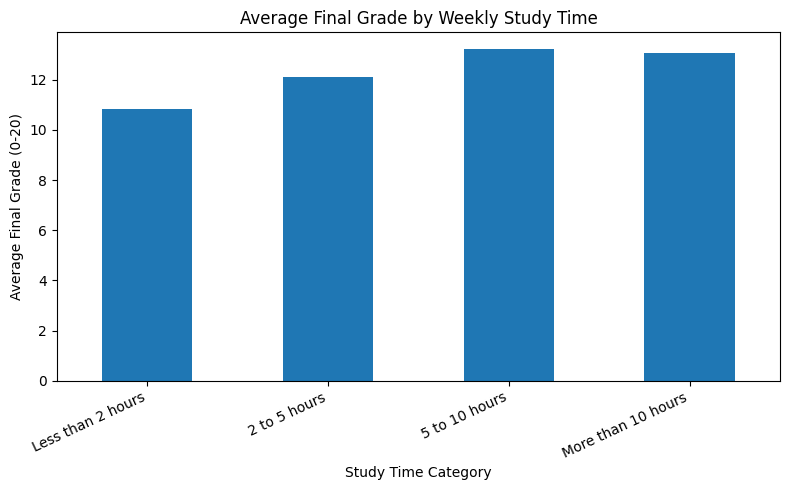

Average final grade for each study-time category:
studytime
1    10.84
2    12.09
3    13.23
4    13.06
Name: G3, dtype: float64


In [118]:

import matplotlib.pyplot as plt

# Calculate average final grade for each study-time category
study_grade = df_clean.groupby("studytime")["G3"].mean()

# Make the bar chart
study_grade.plot(kind="bar", figsize=(8, 5))

plt.title("Average Final Grade by Weekly Study Time")
plt.xlabel("Study Time Category")
plt.ylabel("Average Final Grade (0-20)")
plt.xticks(
    ticks=[0, 1, 2, 3],
    labels=[
        "Less than 2 hours",
        "2 to 5 hours",
        "5 to 10 hours",
        "More than 10 hours"
    ],
    rotation=25,
    ha="right"
)

plt.tight_layout()
plt.savefig("chart1_studytime.png", dpi=150, bbox_inches="tight")
plt.show()

print("Average final grade for each study-time category:")
print(study_grade.round(2))


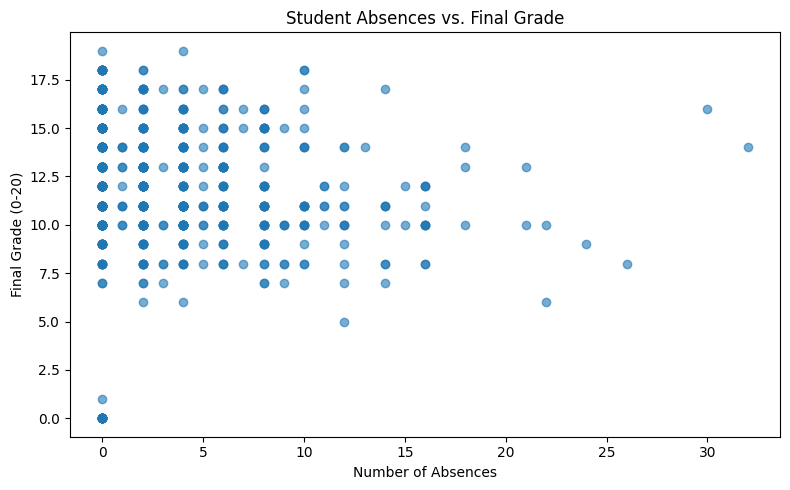

Absences chart created and saved!
Correlation between absences and final grade:
-0.091


In [119]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df_clean["absences"],
    df_clean["G3"],
    alpha=0.6
)

plt.title("Student Absences vs. Final Grade")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade (0-20)")

plt.tight_layout()
plt.savefig("chart2_absences.png", dpi=150, bbox_inches="tight")
plt.show()

print("Absences chart created and saved!")
print("Correlation between absences and final grade:")
print(round(df_clean["absences"].corr(df_clean["G3"]), 3))


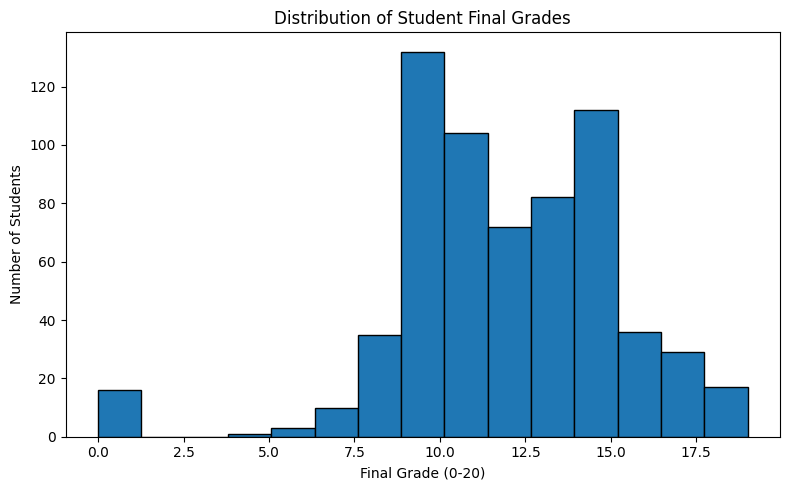

Average final grade: 11.91
Most common final grade: 11
Grade distribution chart created and saved!


In [120]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    df_clean["G3"],
    bins=15,
    edgecolor="black"
)

plt.title("Distribution of Student Final Grades")
plt.xlabel("Final Grade (0-20)")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.savefig("chart3_grade_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print("Average final grade:", round(df_clean["G3"].mean(), 2))
print("Most common final grade:", df_clean["G3"].mode()[0])
print("Grade distribution chart created and saved!")


In [121]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Select the two predictors
X = df_clean[["studytime", "absences"]]

# Select the final grade we want to predict
y = df_clean["G3"]

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

print("Model trained successfully!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Model coefficients:")
print("Study time:", round(model.coef_[0], 3))
print("Absences:", round(model.coef_[1], 3))


Model trained successfully!
Training records: 519
Testing records: 130
Model coefficients:
Study time: 0.966
Absences: -0.045


In [122]:

from sklearn.metrics import mean_absolute_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", round(mae, 2))
print("R-squared (R²):", round(r2, 3))


Mean Absolute Error (MAE): 2.3
R-squared (R²): 0.04


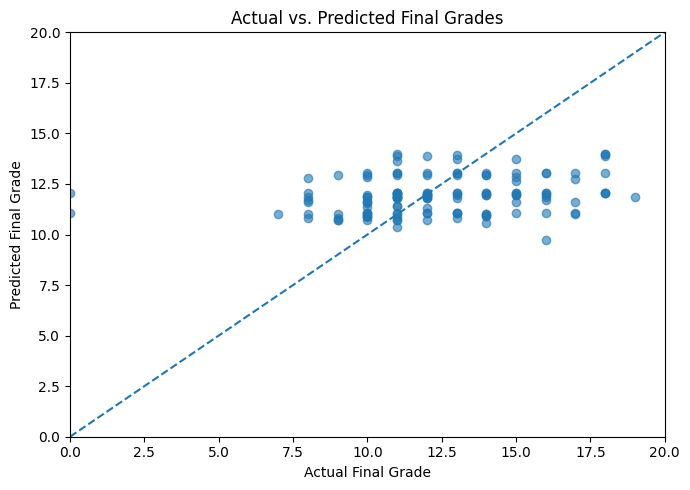

In [123]:

plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([0, 20], [0, 20], linestyle="--")

plt.title("Actual vs. Predicted Final Grades")
plt.xlabel("Actual Final Grade")
plt.ylabel("Predicted Final Grade")

plt.xlim(0, 20)
plt.ylim(0, 20)
plt.tight_layout()

plt.savefig("chart4_actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()


**Findings and Results**

This project explored whether study time and the number of absences could help predict students' final grades. The dataset contained 649 student records. No duplicate rows or missing values were found in the selected columns, so no records were removed during cleaning.

The results showed that students who reported more study time generally had higher average final grades. Students in study-time category 3, representing 5–10 hours of studying per week, had the highest average grade at 13.23 out of 20. Students in category 1, representing less than 2 hours per week, had an average grade of 10.84.

The relationship between absences and final grades was very weak and negative, with a correlation of -0.091. This suggests that absences alone had little linear relationship with final grades in this dataset.

A linear regression model was trained using study time and absences. The model was evaluated on 130 testing records. Its Mean Absolute Error (MAE) was 2.30 grade points, and its R-squared value was 0.04. This means the model explained approximately 4% of the variation in final grades and was not very effective at predicting individual students' grades.

Overall, study time showed a positive association with average final grades, but study time and absences alone were not enough to accurately predict final grades. Other factors, such as previous academic performance, family support, motivation, and learning conditions, may also play a role. These findings show association, not causation.

Student Performance Analysis

About This Project

For my final project, I wanted to look at whether the amount of time students spend studying and the number of times they miss school can help predict their final grades.

I used Python to look through the data, create charts, and build a simple machine learning model. I wanted to see what patterns I could find and how well the model could predict a student's final grade using just these two factors.

My Research Question

Can a student's study time and number of absences help predict their final grade?

Where the Data Came From

I used the Student Performance Dataset from the UCI Machine Learning Repository.

Dataset: https://archive.ics.uci.edu/dataset/320/student+performance

I used the Portuguese course dataset, called `student-por.csv`. It contains information about students and their school performance.

The dataset is licensed under Creative Commons Attribution 4.0 International (CC BY 4.0).

How I Cleaned the Data

The original dataset had 649 rows and 33 columns. I used pandas to load the data and selected the three columns I needed for my project:

- `studytime`: How much time students spend studying each week, recorded in four categories.
- `absences`: The number of school absences.
- `G3`: The student's final grade, on a scale from 0 to 20.

I also checked for duplicate rows and missing values in the columns I selected. There were no duplicates or missing values to remove, so I kept all 649 records.

What I Found

1. Study Time and Final Grades

Students who reported spending more time studying generally had higher average final grades.

Students in category 1, who studied less than 2 hours per week, had an average grade of 10.84. Category 3, representing 5–10 hours of studying per week, had the highest average grade at 13.23.

Interestingly, category 4, which represents more than 10 hours of studying per week, had a slightly lower average grade than category 3.

Average Final Grade by Study Time

2. Absences and Final Grades

I also looked at whether students who missed more school tended to have lower grades. The correlation was -0.091, which is a very weak negative relationship.

This means that, in this dataset, absences by themselves did not have a strong linear relationship with final grades.

Absences vs. Final Grades

3. Distribution of Final Grades

I created a chart to see how final grades were distributed across the students in the dataset.

The average final grade was 11.91 out of 20, and the most common grade was 11.

Distribution of Final Grades

## Building My Prediction Model

After exploring the data, I used linear regression to see how well study time and absences could predict final grades.

I split the data into two groups. I used 519 records to train the model and 130 records to test it.

The model results were:

- Study time coefficient: 0.966
- Absences coefficient: -0.045
- Mean Absolute Error (MAE): 2.30
- R-squared (R²): 0.04

The MAE means that the model's predictions were off by about 2.3 grade points on average. The R² result means the model explained only about 4% of the variation in grades in the test data.

Actual vs. Predicted Final Grades

Looking at these results, I found that the model was not very good at predicting individual students' grades. Even though study time showed a positive relationship with average grades, these two factors were not enough to make accurate predictions.

My Conclusion

Overall, this project helped me see how data can be used to find patterns and test predictions. I found that students who spent more time studying generally had higher average grades, but the relationship was not exactly the same across every study time category.

I also found that absences had a very weak relationship with final grades in this dataset. When I tested my prediction model, the results showed that study time and absences alone could not explain much of the difference in students' grades.

I think adding more information, such as previous grades, motivation, or other factors that affect learning, could help improve the model. One important thing I learned is that finding a relationship between two things does not necessarily mean one causes the other.

Limitations

There are a few things to keep in mind when looking at my results:

- The data came from Portuguese schools, so the results may not apply to every student or school.
- I only used study time and absences to predict grades.
- Study time was recorded in categories rather than exact hours.
- Other things that may affect grades were not included in my model.
- The model had a low R² value, so it was not very effective at predicting individual grades.

Because of these limitations, I would not use this model by itself to make decisions about a student's academic performance.

Tools I Used

- Python
- pandas
- matplotlib
- scikit-learn
- Jupyter Notebook

How to Run My Project

1. Download the `student-por.csv` dataset from the UCI Machine Learning Repository.
2. Open my notebook in Jupyter Notebook or Google Colab.
3. Make sure pandas, matplotlib, and scikit-learn are installed.
4. Update the file path in the notebook to match where the CSV is saved.
5. Run the notebook cells in order to see the data cleaning, charts, and prediction model results.













Student Performance Analysis

About This Project

For my final project, I wanted to look at whether the amount of time students spend studying and the number of times they miss school can help predict their final grades.

I used Python to look through the data, create charts, and build a simple machine learning model. I wanted to see what patterns I could find and how well the model could predict a student's final grade using just these two factors.

My Research Question

Can a student's study time and number of absences help predict their final grade?

Where the Data Came From

I used the Student Performance Dataset from the UCI Machine Learning Repository.

Dataset: https://archive.ics.uci.edu/dataset/320/student+performance

I used the Portuguese course dataset, called `student-por.csv`. It contains information about students and their school performance.

The dataset is licensed under Creative Commons Attribution 4.0 International (CC BY 4.0).

How I Cleaned the Data

The original dataset had 649 rows and 33 columns. I used pandas to load the data and selected the three columns I needed for my project:

- `studytime`: How much time students spend studying each week, recorded in four categories.
- `absences`: The number of school absences.
- `G3`: The student's final grade, on a scale from 0 to 20.

I also checked for duplicate rows and missing values in the columns I selected. There were no duplicates or missing values to remove, so I kept all 649 records.

What I Found

1. Study Time and Final Grades

Students who reported spending more time studying generally had higher average final grades.

Students in category 1, who studied less than 2 hours per week, had an average grade of 10.84. Category 3, representing 5–10 hours of studying per week, had the highest average grade at 13.23.

Interestingly, category 4, which represents more than 10 hours of studying per week, had a slightly lower average grade than category 3.

Average Final Grade by Study Time

2. Absences and Final Grades

I also looked at whether students who missed more school tended to have lower grades. The correlation was -0.091, which is a very weak negative relationship.

This means that, in this dataset, absences by themselves did not have a strong linear relationship with final grades.

Absences vs. Final Grades

3. Distribution of Final Grades

I created a chart to see how final grades were distributed across the students in the dataset.

The average final grade was 11.91 out of 20, and the most common grade was 11.

Distribution of Final Grades

## Building My Prediction Model

After exploring the data, I used linear regression to see how well study time and absences could predict final grades.

I split the data into two groups. I used 519 records to train the model and 130 records to test it.

The model results were:

- Study time coefficient: 0.966
- Absences coefficient: -0.045
- Mean Absolute Error (MAE): 2.30
- R-squared (R²): 0.04

The MAE means that the model's predictions were off by about 2.3 grade points on average. The R² result means the model explained only about 4% of the variation in grades in the test data.

Actual vs. Predicted Final Grades

Looking at these results, I found that the model was not very good at predicting individual students' grades. Even though study time showed a positive relationship with average grades, these two factors were not enough to make accurate predictions.

My Conclusion

Overall, this project helped me see how data can be used to find patterns and test predictions. I found that students who spent more time studying generally had higher average grades, but the relationship was not exactly the same across every study time category.

I also found that absences had a very weak relationship with final grades in this dataset. When I tested my prediction model, the results showed that study time and absences alone could not explain much of the difference in students' grades.

I think adding more information, such as previous grades, motivation, or other factors that affect learning, could help improve the model. One important thing I learned is that finding a relationship between two things does not necessarily mean one causes the other.

Limitations

There are a few things to keep in mind when looking at my results:

- The data came from Portuguese schools, so the results may not apply to every student or school.
- I only used study time and absences to predict grades.
- Study time was recorded in categories rather than exact hours.
- Other things that may affect grades were not included in my model.
- The model had a low R² value, so it was not very effective at predicting individual grades.

Because of these limitations, I would not use this model by itself to make decisions about a student's academic performance.

Tools I Used

- Python
- pandas
- matplotlib
- scikit-learn
- Jupyter Notebook

How to Run My Project

1. Download the `student-por.csv` dataset from the UCI Machine Learning Repository.
2. Open my notebook in Jupyter Notebook or Google Colab.
3. Make sure pandas, matplotlib, and scikit-learn are installed.
4. Update the file path in the notebook to match where the CSV is saved.
5. Run the notebook cells in order to see the data cleaning, charts, and prediction model results.

**AI Use Disclosure**


I used ChatGPT for help understanding parts of the project and an overall idea of how I can complete the assignment to get the best grade, I also used it for a bit more help with working through Python code, troubleshooting errors ( I received alot and wanted to understand what I was doing incorrect), and organizing my report. I ran the code in my notebook and used the results from my analysis to explain my findings.










